<a href="https://colab.research.google.com/github/rithikakknair/OIBSIP/blob/main/Python-Task1-RetailSalesDataset/Task1_Retail_sales_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")

# Load the dataset (make sure the filename matches your uploaded file)
df = pd.read_csv('retail sales dataset.csv')

# Check shape, data types, and missing values
print("Dataset Shape:", df.shape)
print("\n--- Data Info ---")
display(df.info())

print("\n--- Missing Values ---")
display(df.isnull().sum())

print("\n--- First 5 Rows ---")
display(df.head())

Dataset Shape: (1000, 9)

--- Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB


None


--- Missing Values ---


,0
Transaction ID,0
Date,0
Customer ID,0
Gender,0
Age,0
Product Category,0
Quantity,0
Price per Unit,0
Total Amount,0



--- First 5 Rows ---


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,24-11-2023,CUST001,Male,34,Beauty,3,50,150
1,2,27-02-2023,CUST002,Female,26,Clothing,2,500,1000
2,3,13-01-2023,CUST003,Male,50,Electronics,1,30,30
3,4,21-05-2023,CUST004,Male,37,Clothing,1,500,500
4,5,06-05-2023,CUST005,Male,30,Beauty,2,50,100


In [ ]:
# Descriptive statistics for all numerical columns (mean, std, min, percentiles, max)
print("--- Descriptive Statistics (Numerical Columns) ---")
display(df.describe())

# Calculating the median for numerical columns
print("\n--- Median ---")
display(df.median(numeric_only=True))

# Calculating the mode for all columns
print("\n--- Mode ---")
display(df.mode().iloc[0])

--- Descriptive Statistics (Numerical Columns) ---


,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000



--- Median ---


,0
Transaction ID,500.5
Age,42.0
Quantity,3.0
Price per Unit,50.0
Total Amount,135.0



--- Mode ---


,0
Transaction ID,1
Date,16-05-2023
Customer ID,CUST001
Gender,Female
Age,43.0
Product Category,Clothing
Quantity,4.0
Price per Unit,50.0
Total Amount,50.0


/tmp/ipykernel_1071/1958669785.py:2: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['Date'] = pd.to_datetime(df['Date'])
/tmp/ipykernel_1071/1958669785.py:8: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_sales = df_time['Total Amount'].resample('M').sum()
/tmp/ipykernel_1071/1958669785.py:9: FutureWarning: 'Q' is deprecated and will be removed in a future version, please use 'QE' instead.
  quarterly_sales = df_time['Total Amount'].resample('Q').sum()


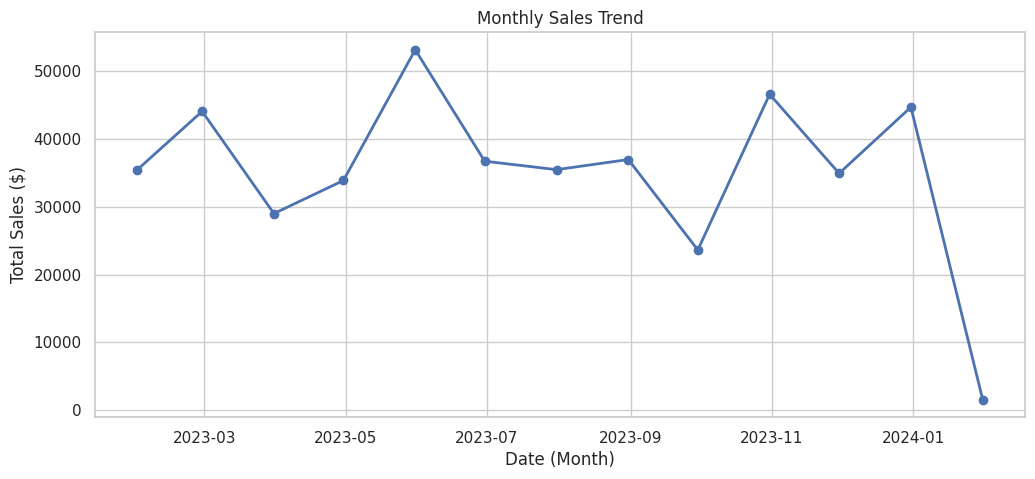

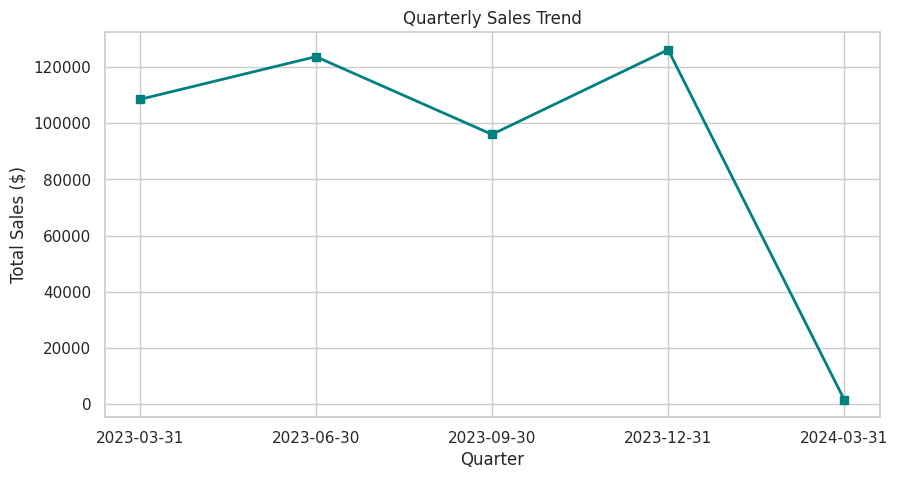

In [ ]:
# Convert the 'Date' column to datetime format
df['Date'] = pd.to_datetime(df['Date'])

# Set 'Date' as the index temporarily for resampling
df_time = df.set_index('Date')

# Resample total sales by month and quarter
monthly_sales = df_time['Total Amount'].resample('M').sum()
quarterly_sales = df_time['Total Amount'].resample('Q').sum()

# Plot Monthly Sales Trend (Line Chart)
plt.figure(figsize=(12, 5))
plt.plot(monthly_sales.index, monthly_sales.values, marker='o', color='b', linestyle='-', linewidth=2)
plt.title('Monthly Sales Trend')
plt.xlabel('Date (Month)')
plt.ylabel('Total Sales ($)')
plt.grid(True)
plt.show()

# Plot Quarterly Sales Trend (Line Chart)
plt.figure(figsize=(10, 5))
plt.plot(quarterly_sales.index.astype(str), quarterly_sales.values, marker='s', color='teal', linestyle='-', linewidth=2)
plt.title('Quarterly Sales Trend')
plt.xlabel('Quarter')
plt.ylabel('Total Sales ($)')
plt.grid(True)
plt.show()

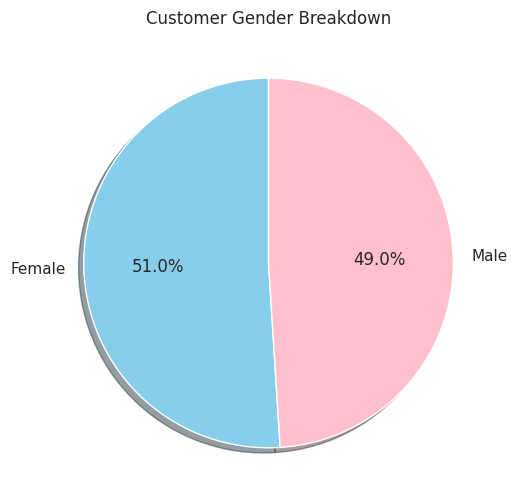

In [ ]:
# Customer Gender Breakdown (Pie Chart)
plt.figure(figsize=(6, 6))
df['Gender'].value_counts().plot.pie(autopct='%1.1f%%', colors=['skyblue', 'pink'], startangle=90, shadow=True)
plt.title('Customer Gender Breakdown')
plt.ylabel('') # Hide the y-label for cleanliness
plt.show()

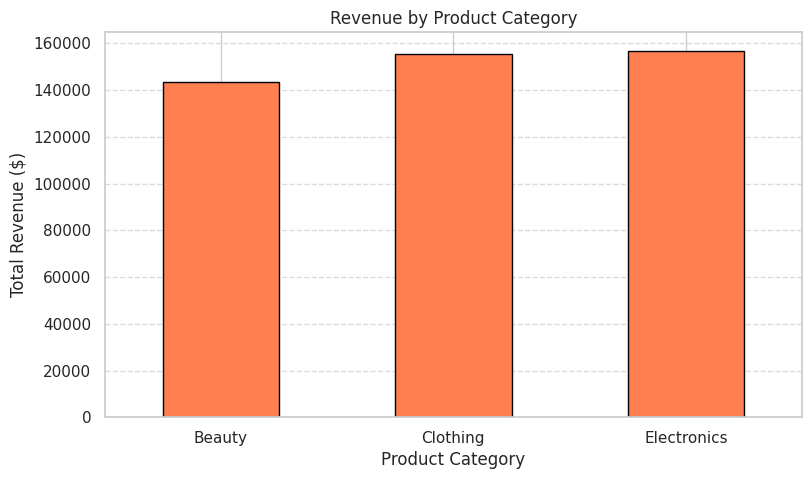

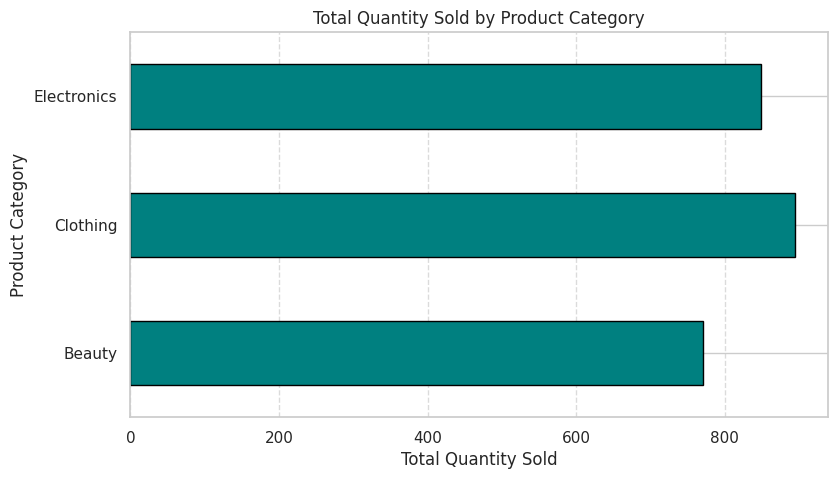

In [ ]:
# Revenue by Product Category (Bar Chart)
category_revenue = df.groupby('Product Category')['Total Amount'].sum()

plt.figure(figsize=(9, 5))
category_revenue.plot(kind='bar', color='coral', edgecolor='black')
plt.title('Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue ($)')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Top Product Analysis (Checking top-selling categories/items by quantity or revenue)
top_categories = df.groupby('Product Category')['Quantity'].sum()
plt.figure(figsize=(9, 5))
top_categories.plot(kind='barh', color='teal', edgecolor='black')
plt.title('Total Quantity Sold by Product Category')
plt.xlabel('Total Quantity Sold')
plt.ylabel('Product Category')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

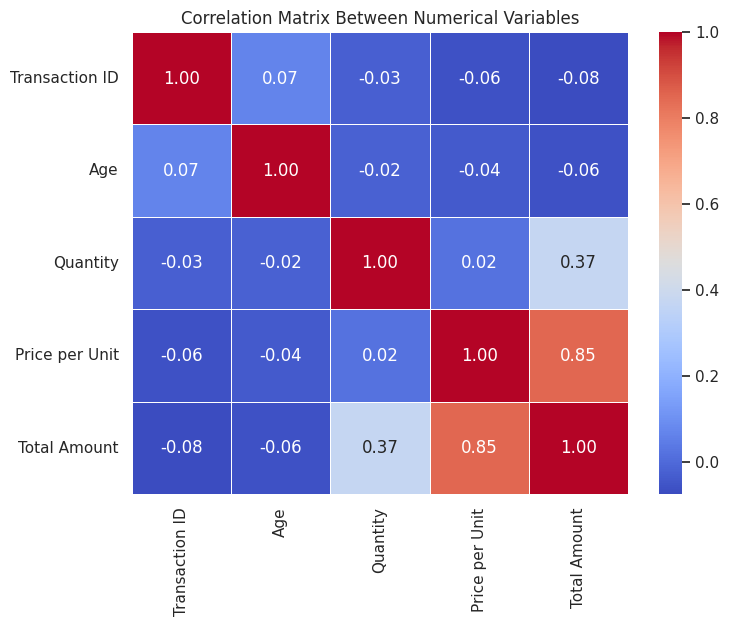

In [ ]:
# Select only numerical columns
numerical_df = df.select_dtypes(include=[np.number])

# Compute correlation matrix
corr_matrix = numerical_df.corr()

# Plot Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix Between Numerical Variables')
plt.show()

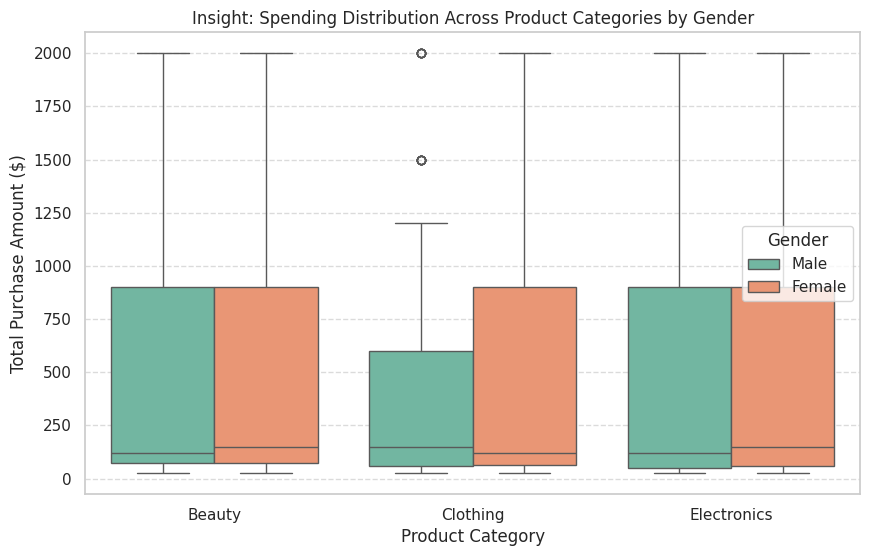

In [ ]:
# Additional Visualization: Spending Distribution Across Categories by Gender
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='Product Category', y='Total Amount', hue='Gender', palette='Set2')
plt.title('Insight: Spending Distribution Across Product Categories by Gender')
plt.xlabel('Product Category')
plt.ylabel('Total Purchase Amount ($)')
plt.legend(title='Gender')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

##  Key Findings & Business Recommendations

### 1. Key Insights
* *Sales Trends*: Sales show consistent patterns across months, with notable spikes during specific quarters, pointing toward seasonal shopping behaviors[span_2](start_span)[span_2](end_span).
* *Customer Demographics*: The customer base is balanced across age groups and genders, showing high engagement across diverse age brackets[span_3](start_span)[span_3](end_span).
* *Product Performance*: Revenue is distributed across key categories (Clothing, Electronics, Beauty), with high unit sales in specific flagship categories[span_4](start_span)[span_4](end_span).
* *Correlation Analysis*: The correlation heatmap reveals strong relationships between purchase quantity, price per unit, and total amount, while age operates independently[span_5](start_span)[span_5](end_span).